In [1]:
import torch

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
X = torch.linspace(-2,2,120)

In [6]:
X

tensor([-2.0000, -1.9664, -1.9328, -1.8992, -1.8655, -1.8319, -1.7983, -1.7647,
        -1.7311, -1.6975, -1.6639, -1.6303, -1.5966, -1.5630, -1.5294, -1.4958,
        -1.4622, -1.4286, -1.3950, -1.3613, -1.3277, -1.2941, -1.2605, -1.2269,
        -1.1933, -1.1597, -1.1261, -1.0924, -1.0588, -1.0252, -0.9916, -0.9580,
        -0.9244, -0.8908, -0.8571, -0.8235, -0.7899, -0.7563, -0.7227, -0.6891,
        -0.6555, -0.6218, -0.5882, -0.5546, -0.5210, -0.4874, -0.4538, -0.4202,
        -0.3866, -0.3529, -0.3193, -0.2857, -0.2521, -0.2185, -0.1849, -0.1513,
        -0.1176, -0.0840, -0.0504, -0.0168,  0.0168,  0.0504,  0.0840,  0.1176,
         0.1513,  0.1849,  0.2185,  0.2521,  0.2857,  0.3193,  0.3529,  0.3866,
         0.4202,  0.4538,  0.4874,  0.5210,  0.5546,  0.5882,  0.6218,  0.6555,
         0.6891,  0.7227,  0.7563,  0.7899,  0.8235,  0.8571,  0.8908,  0.9244,
         0.9580,  0.9916,  1.0252,  1.0588,  1.0924,  1.1261,  1.1597,  1.1933,
         1.2269,  1.2605,  1.2941,  1.32

In [16]:
#j'ai besoin de rajouter une dimension; j'ai un input avec une seule variable
X = torch.linspace(-2,2,50).unsqueeze(1)

In [17]:
X

tensor([[-2.0000],
        [-1.9184],
        [-1.8367],
        [-1.7551],
        [-1.6735],
        [-1.5918],
        [-1.5102],
        [-1.4286],
        [-1.3469],
        [-1.2653],
        [-1.1837],
        [-1.1020],
        [-1.0204],
        [-0.9388],
        [-0.8571],
        [-0.7755],
        [-0.6939],
        [-0.6122],
        [-0.5306],
        [-0.4490],
        [-0.3673],
        [-0.2857],
        [-0.2041],
        [-0.1224],
        [-0.0408],
        [ 0.0408],
        [ 0.1224],
        [ 0.2041],
        [ 0.2857],
        [ 0.3673],
        [ 0.4490],
        [ 0.5306],
        [ 0.6122],
        [ 0.6939],
        [ 0.7755],
        [ 0.8571],
        [ 0.9388],
        [ 1.0204],
        [ 1.1020],
        [ 1.1837],
        [ 1.2653],
        [ 1.3469],
        [ 1.4286],
        [ 1.5102],
        [ 1.5918],
        [ 1.6735],
        [ 1.7551],
        [ 1.8367],
        [ 1.9184],
        [ 2.0000]])

In [18]:
print(X.shape)

torch.Size([50, 1])


In [19]:
Y = 3 * X + 2

In [20]:
#faire un plot de y
import matplotlib.pyplot as plt


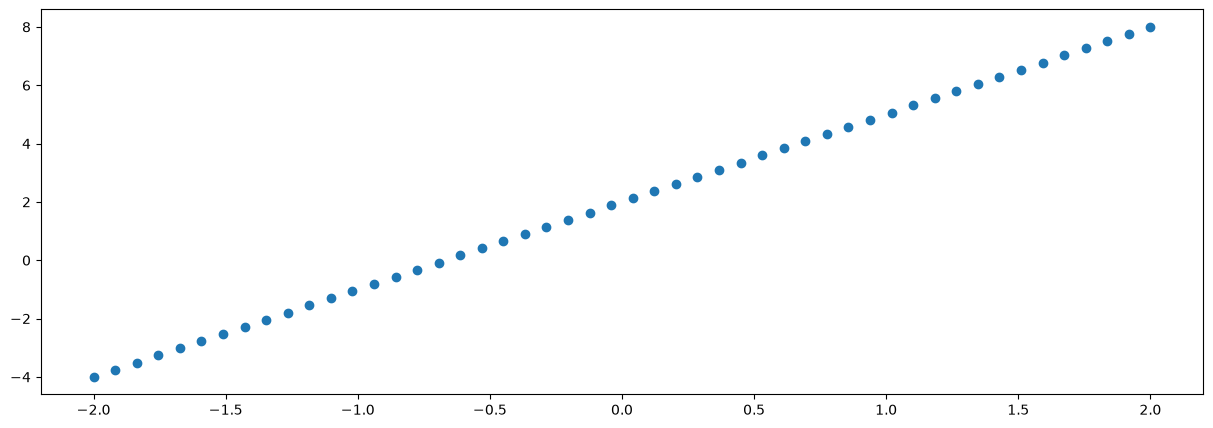

In [24]:
plt.figure(figsize=(15,5))
plt.scatter(X,Y)

In [25]:
# je vais ajouter un bruit pour créer un nuage de point
# je vais créer un bruit gaussien 

In [26]:
#je veux un bruit aléatoire avec la meme dimension que X
noise = 0.6 * torch.randn_like(X) #genere un un nombre aleatoire entre 0 et 1 qui va prendre la meme dimension que X
Y = 3 * X + 2 + noise

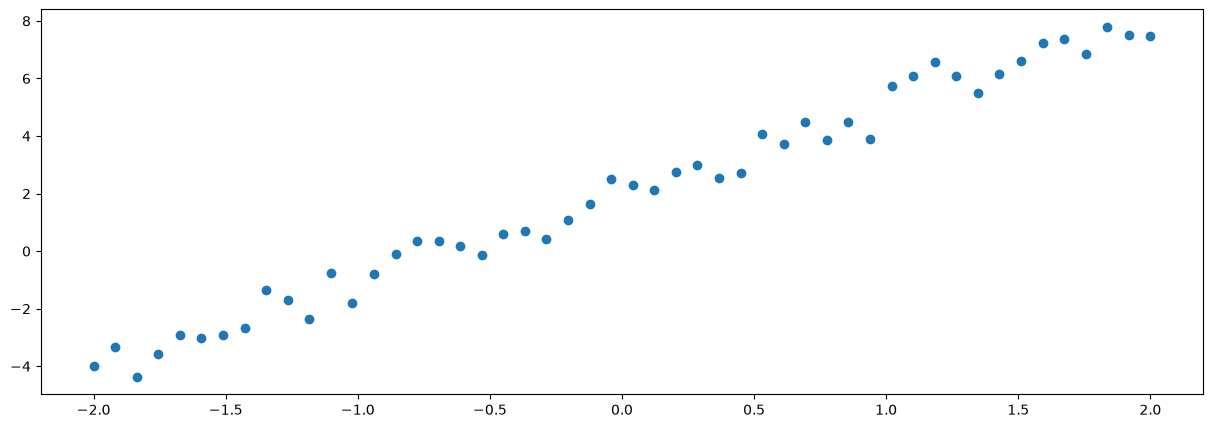

In [27]:
plt.figure(figsize=(15,5))
plt.scatter(X,Y)

In [28]:
# trouver une droite qui va ajuster le nuage de point

In [30]:
## utilisons un reseau de neuronne
import torch.nn as nn #tous les classe concernant le reseau de neurone se trouve dans ce package


In [31]:
#model lineaire avec une seul variable input, un seul neurone output
model =nn.Linear(1,1)

In [33]:
# une fois que je crée le model je dois l'entrainer
#1.1 quel est le Loss que je vais utiliser?
loss_function = nn.MSELoss()
#1.2 Quel est l'algorithme qui va faire l'optimisation? Quel est l'algo qui mettre à jour les parametres du modele
    # pour minimiser le loss? R: c'est ce qu'on appelle l'optimizer ex:Adam, SGD, ...
optimizer = torch.optim.Adam(model.parameters(),lr=0.01) # Adam va optimiser les parametre du model fourni

#1.3 faire la boucle d'apprentissage
epochs = 500 # c'est un hyperparamètre

for epoch in range(epochs):
    #1.3.1 forward <=> calcul des predictions
    Y_pred = model(X)
    #1.3.2 Calcul de la perte(Loss)
    loss = loss_function(Y,Y_pred)
    #1.3.3 Rétropropagation(backward)<=>Calculer le Gradient <=> il revient sur le graph des operateurs 
    # et il calcul le gradient de tous les parametres
    optimizer.zero_grad() #initialiser d'abord le gradient à 0
    loss.backward()
    #1.3.4 je demande a l'optimizer:  Va me changer les parametres qui permettent de minimiser le loss
    optimizer.step()
    if epoch % 100 == 0 :
        print(f"Epoch : {epoch}/{epochs}, loss = {loss.item()}")
        

    
    


Epoch : 0/500, loss = 12.8178071975708
Epoch : 100/500, loss = 4.838479042053223
Epoch : 200/500, loss = 1.5462651252746582
Epoch : 300/500, loss = 0.5191879868507385
Epoch : 400/500, loss = 0.27550724148750305


In [34]:
# evaluation
with torch.inference_mode():
    pred = model(X)
    


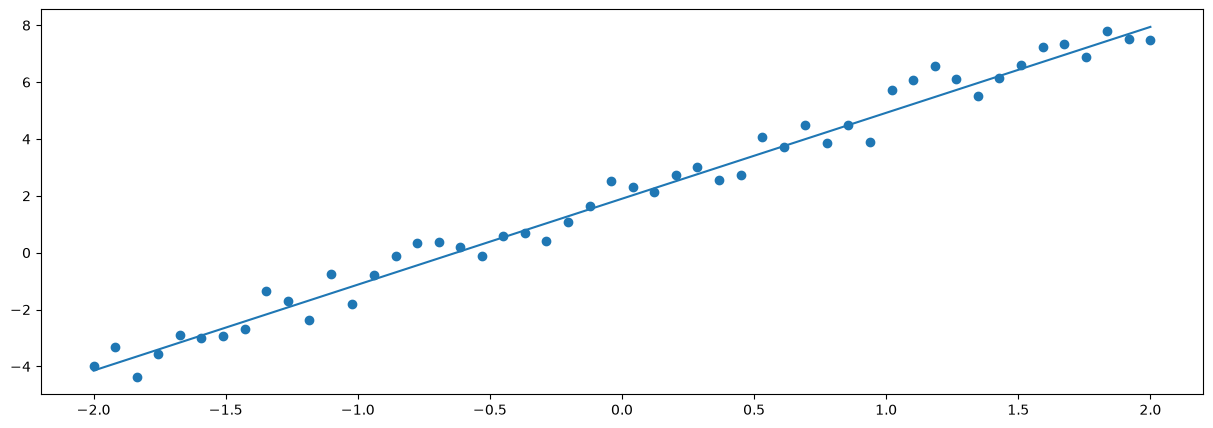

In [35]:
plt.figure(figsize=(15,5))
plt.scatter(X,Y)
plt.plot(X,pred)

In [36]:
from torcheval.metrics import R2Score

In [37]:
r2_score = R2Score()
r2_score.update(Y,pred)
score =r2_score.compute()

In [38]:
print(score)

tensor(0.9818)


In [54]:
# une fois que je crée le model je dois l'entrainer
#1.1 quel est le Loss que je vais utiliser?
loss_function = nn.MSELoss()
#1.2 Quel est l'algorithme qui va faire l'optimisation? Quel est l'algo qui mettre à jour les parametres du modele
    # pour minimiser le loss? R: c'est ce qu'on appelle l'optimizer ex:Adam, SGD, ...
optimizer = torch.optim.Adam(model.parameters(),lr=0.01) # Adam va optimiser les parametre du model fourni

#1.3 faire la boucle d'apprentissage
epochs = 100 # c'est un hyperparamètre
losses =[]

for epoch in range(epochs):
    #1.3.1 forward <=> calcul des predictions
    Y_pred = model(X)
    #1.3.2 Calcul de la perte(Loss)
    loss = loss_function(Y,Y_pred)
    #1.3.3 Rétropropagation(backward)<=>Calculer le Gradient <=> il revient sur le graph des operateurs 
    # et il calcul le gradient de tous les parametres
    optimizer.zero_grad() #initialiser d'abord le gradient à 0
    loss.backward()
    #1.3.4 je demande a l'optimizer:  Va me changer les parametres qui permettent de minimiser le loss
    optimizer.step()
    losses.append(loss.item())
    if epoch % 10 == 0 :
        print(f"Epoch : {epoch}/{epochs}, loss = {loss.item()}")
        

Epoch : 0/100, loss = 0.22338372468948364
Epoch : 10/100, loss = 0.22344304621219635
Epoch : 20/100, loss = 0.2233978658914566
Epoch : 30/100, loss = 0.22338399291038513
Epoch : 40/100, loss = 0.22338424623012543
Epoch : 50/100, loss = 0.2233840972185135
Epoch : 60/100, loss = 0.2233838438987732
Epoch : 70/100, loss = 0.22338372468948364
Epoch : 80/100, loss = 0.22338370978832245
Epoch : 90/100, loss = 0.22338372468948364


In [55]:
# evaluation
with torch.inference_mode():
    pred = model(X)
    

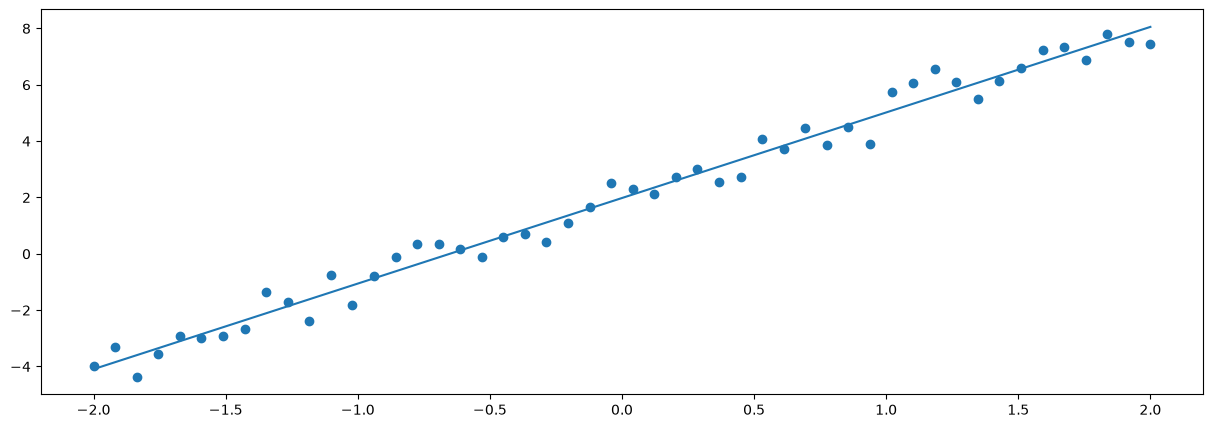

In [57]:
plt.figure(figsize=(15,5))
plt.scatter(X,Y)
plt.plot(X,pred)

In [61]:
r2_score = R2Score()
r2_score.update(Y,pred)
score =r2_score.compute()

In [60]:
print(score)

tensor(0.9826)


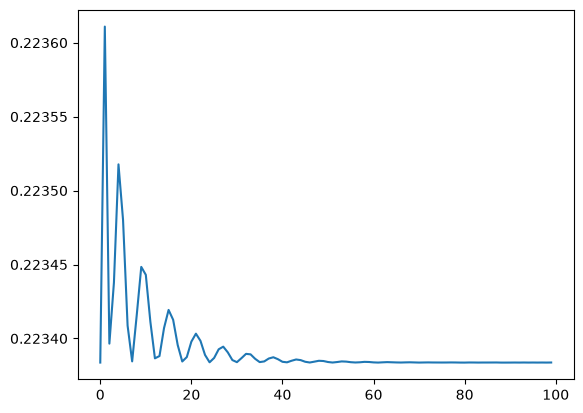

In [62]:
plt.plot(losses)